# First Implementation of the RSA model 

In [1]:
import numpy as np 
import random as rd
import random as rd
import json 
import logging
import matplotlib.pyplot as plt
#sys.path.insert(1, '/home/user/Documents/Sprachgebrauchsmodellierung_RSA/Hausarbeit_RSA/repo/scripts/')
#sys.path.insert(1, 'D:StandardLibs/documents/Uni/Sprachgebrauchsmodellierung_RSA/Hausarbeit/imposter_RSA/scripts/')
from gamestate import GameState


In [64]:
import pathlib

In [2]:
dummy_vocab=["Löwe", "Pfote", "Zoo", "Schrank", "Katze", "Haustier"]
gs = GameState(dummy=True, sim_file="../output/exp_sims.npy", dummy_vocab=dummy_vocab, target="Löwe")

randomly chosen target word: Löwe
randomly chosen play order: ['P3', 'P1', 'P2']
similarity table loaded from ../output/exp_sims.npy


In [3]:
print(gs.V)
print(gs.SIMS["P1"])

['Löwe', 'Pfote', 'Zoo', 'Schrank', 'Katze', 'Haustier']
[[0.         0.28233542 0.2422133  0.03221552 0.28233542 0.1622967 ]
 [0.28233542 0.         0.15353181 0.19377627 0.91687398 0.51362782]
 [0.2422133  0.15353181 0.         0.         0.15353181 0.19384804]
 [0.03221552 0.19377627 0.         0.         0.19377627 0.15339655]
 [0.28233542 0.91687398 0.15353181 0.19377627 0.         0.51362782]
 [0.1622967  0.51362782 0.19384804 0.15339655 0.51362782 0.        ]]


In [4]:
logger = logging.getLogger(__name__)
logging.basicConfig(filename='../output/logs/probs.log', level=logging.INFO)

In [ ]:
class Speaker_Agent:
    def __init__(self, player, i_weight=0.6): 
        self.player = player
        self.role = gs.ROLES[player]
        self.alpha = gs.RATIONALITY[player]
        self.priors = self.get_priors_per_player()
        self.i_weight = i_weight
        # während 1 - L0(t|u,i) die Warhscheinlichkeitsmasse von 5/6 der Kandidaten auf sich versammelt, versammelt L0(i|u,t) nur die Warhscheinlichkeitsmasse der Hälfte der möglichen Kandidaten auf sich. Wir entscheiden uns daher dafür, den zweiten Teil der Funktion mit dem Faktor 1/2 * 6/5 = 3/5 zu gewichten. Macht das Sinn?

    def get_priors_per_player(self): 
        priors = {p: {} for p in gs.PLAYERS}
        for p in gs.PLAYERS: 

            for role in ["imposter", "agent"]: 
                if role=="imposter":
                    ki = True
                    kt = False
                else:
                    ki = False
                    kt = True

                i_priors, t_priors = self.get_priors(p, knows_t=kt, knows_imp=ki)
                priors[p][role]={}
                priors[p][role]["i"]=i_priors
                priors[p][role]["t"]=t_priors
        return(priors)



    def get_priors(self, player, knows_t = True, knows_imp = False):
        i_priors = []
        t_priors = []
        # P1 weiß nicht wer der Imposter ist 
        for p in gs.PLAYERS: 
            if knows_imp: 
                if p==player: 
                    i_priors.append(1)
                else:
                    i_priors.append(0)
            else:
                if p==player:
                    i_priors.append(0)
                else: 
                    p_num = len(gs.PLAYERS)
                    i_priors.append(1/(p_num-1))
        
        for w in gs.V: 
            if knows_t: 
                if w==gs.TARGET:
                    t_priors.append(1)
                else:
                    t_priors.append(0)
            else:
                t_priors.append(gs.FREQ_NORMED[w])
                                
                    
        i_priors = np.array(i_priors)
        t_priors = np.array(t_priors)

        return((i_priors, t_priors))
    

    def get_P_u_w(self,u,w,speaker="P1", listener="P2"):
        imp_ind, t_ind = w
        # sollte so passen, weil wenn L=imp sind Berechnungen egal, in denen nicht S = imp
        # kommt mir sehr sus vor - warum wird einmal die ähnlichkeit mit dem in der welt enthalteten target berechnet und einmal mit dem target von imp?
        if gs.PLAYERS[imp_ind]==speaker: 
            P_u_w = sum([self.priors[speaker]["imposter"]["t"][n] * gs.SIMS[listener][n, u] for n in range(len(gs.V))])
        else:
            P_u_w = gs.SIMS[listener][t_ind, u]
            
        return(P_u_w)

    def L0_a(self, u, w, listener="P2", speaker="P1"):
        # literal listener function for agents 
        #logger.info(f"calculating P({w}|{u}) for L0...")
        imp, t = w
        imp = gs.PLAYERS.index(imp)
        t = gs.V.index(t)        
        u = gs.V.index(u)
        priors_l = self.priors[listener]

        #logger.info(f"P(u|w) in L(0): {self.get_P_u_w(u,(imp,t),t_imp) }, priors: {priors_l[imp][t]}")
        P_w_u = self.get_P_u_w(u,(imp,t), speaker=speaker, listener=listener) * priors_l["agent"]["i"][imp]
        #logger.info(f"P(w|u) in L(0): {P_w_u}")
        SUM = np.nansum([self.get_P_u_w(u,(i_n, t), speaker=speaker) * priors_l["agent"]["i"][i_n] for i_n in range(len(gs.PLAYERS))])
        #logger.info(f"SUM in L0: {SUM}")
        if SUM==0:
            P_w_u = 0
        else:    
            P_w_u = P_w_u/SUM
            
        #logger.info(f"normalized P(w|u) in L(0): {P_w_u}")

        return(P_w_u)


    
    def get_P_u_t(self,u,t, listener="P3"): 

        P_u_t = gs.SIMS[listener][t, u]

        return(P_u_t)

    
    def L0_t(self, u, t, listener="P3"): 
        # literal listener function for the imposter
        t = gs.V.index(t)
        u = gs.V.index(u)
        priors_l = self.priors[listener]
        P_t_u = self.get_P_u_t(u,t, listener=listener) * priors_l["imposter"]["t"][t]
        SUM = np.nansum([self.get_P_u_t(u,t_n, listener=listener) * priors_l["imposter"]["t"][t_n] for t_n in range(len(gs.V))])
        if SUM==0:
            P_t_u = 0
        else:    
            P_t_u = P_t_u/SUM
        return(P_t_u)
    
    def utility(self, u, i, t, speaker="P1", adversarial=True, log=True):
        partner = [p for p in gs.PLAYERS if not p in [speaker, i]][0]
        l0_a = self.L0_a(u,(i,t),listener=partner, speaker=speaker)
        U_a = l0_a#np.log(l0_i)
        if adversarial: 
            l0_i = self.L0_t(u,t,listener=i)
            U_i = l0_i#np.log(l0_t)
            U = U_a - self.i_weight * U_i#+ i_weight * U_i
            if log: 
                logger.info(f"outputs of L0 functions within utility function: L0(t|u): {l0_i}, L0(i|u): {l0_a}")
                logger.info(f"imposter component of utility function: {U_i}\nagent component of utility function: {U_a}")
        else:
            U = U_a
            if log: 
                logger.info(f"output of L0 function within utility function: L0(i|u): {l0_a}")

        return(U)
    
    def S1_i_t(self, u, i, t, alpha=1, speaker="P1", i_weight=1.0, adversarial=True):
        # gets other player that is not imposter
        partner = [p for p in gs.PLAYERS if not p in [speaker,i]][0]
        #P_u = np.exp(alpha*self.utility(u,i,t, partner=partner, speaker=speaker, log=True, i_weight=i_weight))
        #P_u = np.exp(alpha*self.utility(u,i,t, speaker=speaker, log=True, i_weight=i_weight, adversarial=adversarial))
        P_u = alpha*self.utility(u,i,t, speaker=speaker, log=True, i_weight=i_weight, adversarial=adversarial)
        #SUM = np.nansum([np.exp(alpha*self.utility(u_n, i, t, speaker=speaker, adversarial=adversarial)) for u_n in gs.V])
        SUM = np.nansum([alpha*self.utility(u_n, i, t, speaker=speaker, adversarial=adversarial) for u_n in gs.V])
        if SUM==0:
            P_u = 0
        else:
            P_u = P_u/SUM

        return(P_u)
    
    def S1_certain(self, u, t, speaker="P1", alpha=1, i_weight=1.0, adversarial=True): 
        
        def get_i_sum(u,t,speaker="P1", alpha=1, log=False):
            P_u = [self.priors[speaker]["agent"]["i"][gs.PLAYERS.index(i)] * self.S1_i_t(u,i,t, alpha=alpha, speaker=speaker, i_weight=i_weight, adversarial=adversarial) for i in gs.PLAYERS if i!=self.player]
            if log: 
                for n, p in enumerate([player for player in gs.PLAYERS if player!=self.player]):
                    logger.info(f"S1(u|{p},{gs.TARGET})={P_u[n]}")
            P_u_sum = np.nansum(P_u)
            return(P_u_sum)

        P_u = get_i_sum(u,t,speaker=speaker, alpha=alpha, log=True)
        SUM = np.nansum([get_i_sum(u_n,t,speaker=speaker, alpha=alpha) for u_n in gs.V])
        if SUM == 0: 
            P_u = 0 
        else:
            P_u = P_u/SUM
        return(P_u)
        

In [6]:
a1 = Speaker_Agent("P1")

In [7]:
a1.priors

{'P1': {'imposter': {'i': array([1, 0, 0]),
   't': array([0.16666667, 0.16666667, 0.16666667, 0.16666667, 0.16666667,
          0.16666667])},
  'agent': {'i': array([0. , 0.5, 0.5]), 't': array([1, 0, 0, 0, 0, 0])}},
 'P2': {'imposter': {'i': array([0, 1, 0]),
   't': array([0.16666667, 0.16666667, 0.16666667, 0.16666667, 0.16666667,
          0.16666667])},
  'agent': {'i': array([0.5, 0. , 0.5]), 't': array([1, 0, 0, 0, 0, 0])}},
 'P3': {'imposter': {'i': array([0, 0, 1]),
   't': array([0.16666667, 0.16666667, 0.16666667, 0.16666667, 0.16666667,
          0.16666667])},
  'agent': {'i': array([0.5, 0.5, 0. ]), 't': array([1, 0, 0, 0, 0, 0])}}}

In [37]:
word_rows = []
for u in gs.V:
    t_prob = a1.L0_t(u, gs.TARGET)
    i_prob =  a1.L0_a(u, ("P3",gs.TARGET))
    s1_prob = a1.S1_i_t(u, "P3", gs.TARGET, adversarial=True)
    for prob_name, prob in zip(["L0_t", "L0_i", "S1"], [t_prob, i_prob, s1_prob]):
        row_dic = {"word": u, "prob_type": prob_name, "prob": prob}
        word_rows.append(row_dic)


- folgt Ähnlichkeit

In [ ]:
for u in gs.V:
    i_prob =  a1.L0_a(u, ("P1",gs.TARGET))
    print(u, a1.L0_a(u, ("P1",gs.TARGET)))


Löwe 1.0
Pfote 0.5487636359763105
Zoo 0.33833698232561527
Schrank 0.7478098095232069
Katze 0.5487636359763105
Haustier 0.6121289385476512


In [15]:
for u in gs.V:
    print(u, a1.L0_a(u, ("P3",gs.TARGET)))

Löwe 0.0
Pfote 0.4512363640236895
Zoo 0.6616630176743846
Schrank 0.25219019047679314
Katze 0.4512363640236895
Haustier 0.3878710614523489


- je ähnlicher, desto wahrhscheinlicher ist der Sprecher kein Imposter
- ABER: selbst für ähnlichstes Wort > 50%

In [ ]:
for u in gs.V:
    util = a1.utility(u, "P3", gs.TARGET, adversarial=True)
    print(u, util)


Löwe 0.0
Pfote 0.3141900006348051
Zoo 0.33572415975117137
Schrank 0.1959837889592767
Katze 0.3141900006348051
Haustier 0.28226393713944975


- für ähnlichere Wörter ist utility ohne adversarial höher 
- adversarial schwächt das ab, hängt aber wahrscheinlich von Gewichtung ab 

- wie für Utility 

In [17]:
for u in gs.V:
    print(u, a1.S1_certain(u, gs.TARGET))


Löwe 0.0
Pfote 0.2178317256978584
Zoo 0.23276161854070115
Schrank 0.13587793014274208
Katze 0.2178317256978584
Haustier 0.19569699992083997


- gleich wie letzte Funktion bei gleichen Priors - ist zu erwarten

In [18]:
print(gs.V)

['Löwe', 'Pfote', 'Zoo', 'Schrank', 'Katze', 'Haustier']


In [23]:
# change priors to test how it changes output of S1_certain 

#a1.priors["P1"]["agent"]["i"]=[0,0.3,0.7]
a1.priors["P2"]["imposter"]["t"]=[0.2, 0.05, 0.15, 0.05, 0.5, 0.05]

In [24]:
for u in gs.V:
    print(u, a1.S1_i_t(u, "P3", gs.TARGET, adversarial=True), a1.S1_i_t(u, "P3", gs.TARGET, adversarial=False))

Löwe 0.0 0.0
Pfote 0.2178317256978584 0.20471689440852553
Zoo 0.23276161854070115 0.30018324967302984
Schrank 0.13587793014274208 0.11441363487272758
Katze 0.2178317256978584 0.20471689440852553
Haustier 0.19569699992083997 0.17596932663719142


- für i=P3 keine Veränderung

In [25]:
for u in gs.V:
    print(u, a1.S1_i_t(u, "P2", gs.TARGET, adversarial=True), a1.S1_i_t(u, "P2", gs.TARGET, adversarial=False))

Löwe 0.0 0.0
Pfote 0.27798991928229994 0.20471689440852553
Zoo 0.2536832659003291 0.30018324967302984
Schrank 0.15667436833211654 0.11441363487272758
Katze 0.07871201396005835 0.20471689440852553
Haustier 0.23294043252519603 0.17596932663719142


- Pferd und Hund kriegen einen Boost auf Kosten von Katze 
- v.a. wird aber Pferd geboostet (auch wenn es immer noch nicht Nr. 1 ist), was Sinn ergibt, weil P2 falls Imposter schon auf dem Holzweg ist 

In [26]:
for u in gs.V:
    print(u, a1.S1_certain(u, gs.TARGET))


Löwe 0.0
Pfote 0.2479108224900792
Zoo 0.24322244222051514
Schrank 0.14627614923742935
Katze 0.1482718698289584
Haustier 0.21431871622301804


In [57]:
word_rows_certain = []
for u in gs.V:
    s1_prob_p2 = a1.S1_i_t(u, "P2", gs.TARGET, adversarial=True)
    s1_prob_p3 = a1.S1_i_t(u, "P3", gs.TARGET, adversarial=True)
    s1_prob_certain = a1.S1_certain(u, gs.TARGET)
    for prob_name, prob in zip(["S1_p2", "S1_p3", "S1_certain"], [s1_prob_p2, s1_prob_p3, s1_prob_certain]):
        row_dic = {"word": u, "prob_type": prob_name, "prob": prob}
        word_rows_certain.append(row_dic)


3 Szenarien: 

1. Erster Zug, noch nichts ist passiert, unfiforme priors 
2. Zweiter Zug, P2 hat etwas gesagt, das suggeriert, dass er auf dem Holzweg ist (Targetwort-Priors für P2-i sind hoch für das falsche Wort, Imposter-Priors für P2 sind hoch) 
3. Zweiter Zug, P2 hat etwas gesagt, das suggeriert, dass der ein Agent ist (Targetwort-Priors für P2-i sind hoch für das Targetwort, Imposter-Priors für P2 sind niedrig), P1 und P2 haben neulich Narnia gesehen, in dem ein Löwe und ein Schrank vorkommen - diese Ähnlichkeiten setzen wir manuell hoch - Schrank eignet sich perfekt, um P2 die eigene Identität mitzuteilen ohne P3 weiterzubringen. 

Wörter

Löwe 
Käfig
Mähne 
Schrank 
Hund 
Leine 

Targetwort Löwe 

2. gesagtes Wort könnte Leine sein -> Käfig wäre wahrscheinlich gut, weil ähnlich zu Löwe und Hund 
3. gesagtes Wort könnte Käfig sein -> 

- v.a. hat Katze verloren und Pferd gewonnen - wie zu erwarten, siehe letzte Funktion
- Katze ist deutlich riskanter, da sehr geringe Ähnlichkeit mit Stall und höchste Ähnlichkeit mit Dino 

In [9]:
a1.S1_certain(gs.V[2], gs.TARGET, i_weight=1.0)

np.float64(0.10318440153522661)

In [9]:
output_ps = [a1.S1_certain(w, gs.TARGET, i_weight=1.0) for w in gs.V]
print(output_ps)

[np.float64(0.10721105764451906), np.float64(0.10851971759401698), np.float64(0.10073419320564458), np.float64(0.10797562764285046), np.float64(0.1085264297540778), np.float64(0.1069120459880072), np.float64(0.07426318986446995), np.float64(0.10732722941912319), np.float64(0.10426731902282088), np.float64(0.07426318986446995)]


In [10]:
output_ps_2 = [a1.S1_certain(w, gs.TARGET, i_weight=2.5) for w in gs.V]
print(output_ps_2)

[np.float64(0.08818382559772178), np.float64(0.10059005623398591), np.float64(0.11366552486628433), np.float64(0.0926194210388638), np.float64(0.09980439325626239), np.float64(0.10906627408627122), np.float64(0.09744468638584819), np.float64(0.08876886171834321), np.float64(0.11241227043057103), np.float64(0.09744468638584819)]


In [27]:
import seaborn as sns
import pandas as pd

In [30]:
penguins = sns.load_dataset("penguins")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


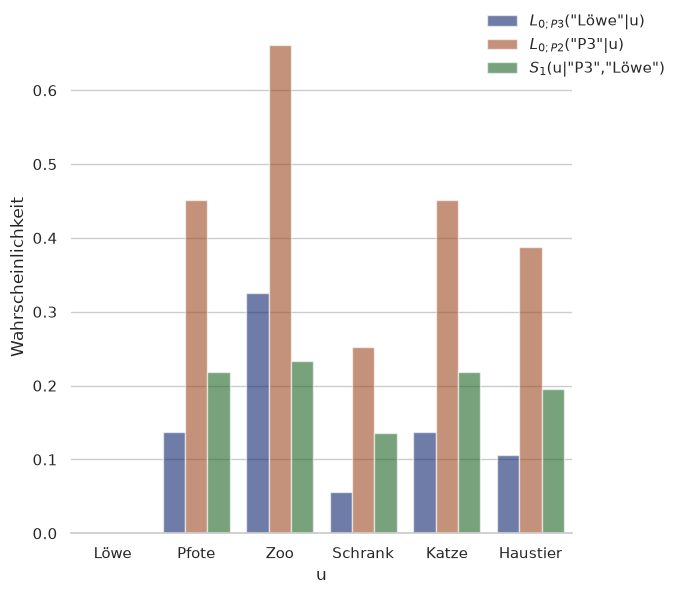

In [ ]:
def create_L_diagram(word_rows, output_file="../output/plots/L_plot.png"):
    sns.set_theme(style="whitegrid")

    g = sns.catplot(
        data=pd.DataFrame(word_rows), kind="bar",
        x="word", y="prob", hue="prob_type",
        palette="dark", alpha=.6, height=6
    )
    g.despine(left=True)
    g.set_axis_labels("u", "Wahrscheinlichkeit")
    g.legend.set_title("")
    new_labels = ['$L_{0;P3}$("Löwe"|u)', '$L_{0;P2}$("P3"|u)', '$S_{1}$(u|"P3","Löwe")']
    for t, l in zip(g._legend.texts, new_labels):
        t.set_text(l)
    sns.move_legend(g, "upper right")
    fig = g.fig
    fig.savefig(output_file) 
    return

create_L_diagram(word_rows)

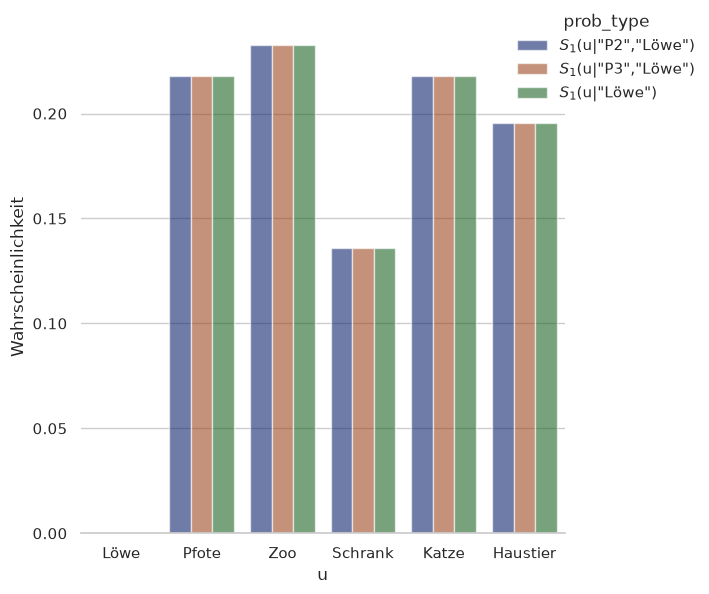

In [66]:
def create_S_diagram(word_rows, output_file="../output/plots/S_plot.png"):
    sns.set_theme(style="whitegrid")

    # Draw a nested barplot by species and sex
    g = sns.catplot(
        data=pd.DataFrame(word_rows_certain), kind="bar",
        x="word", y="prob", hue="prob_type",
        palette="dark", alpha=.6, height=6
    )#
    g.despine(left=True)
    g.set_axis_labels("u", "Wahrscheinlichkeit")
    #g.legend.set_title("")
    new_labels = ['$S_{1}$(u|"P2","Löwe")', '$S_{1}$(u|"P3","Löwe")', '$S_{1}$(u|"Löwe")'] 
    for t, l in zip(g._legend.texts, new_labels):
        t.set_text(l)
    sns.move_legend(g, "upper right")
    fig = g.fig
    fig.savefig(output_file) 
    return 

create_S_diagram(word_rows_certain)

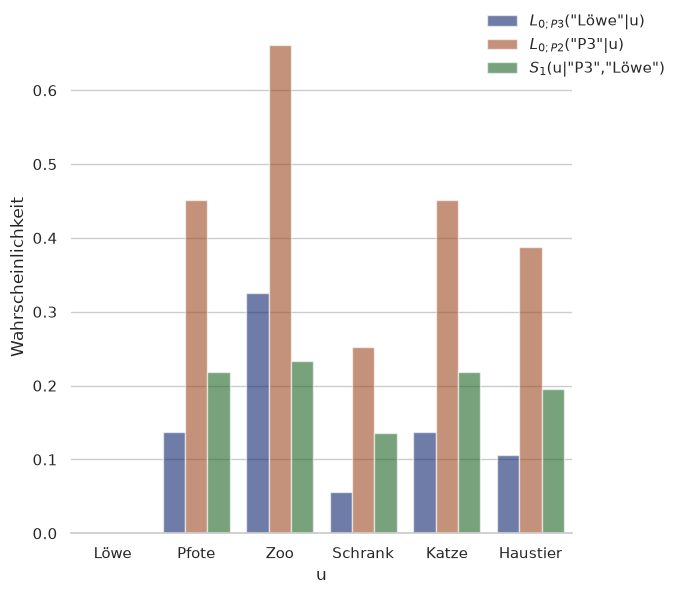

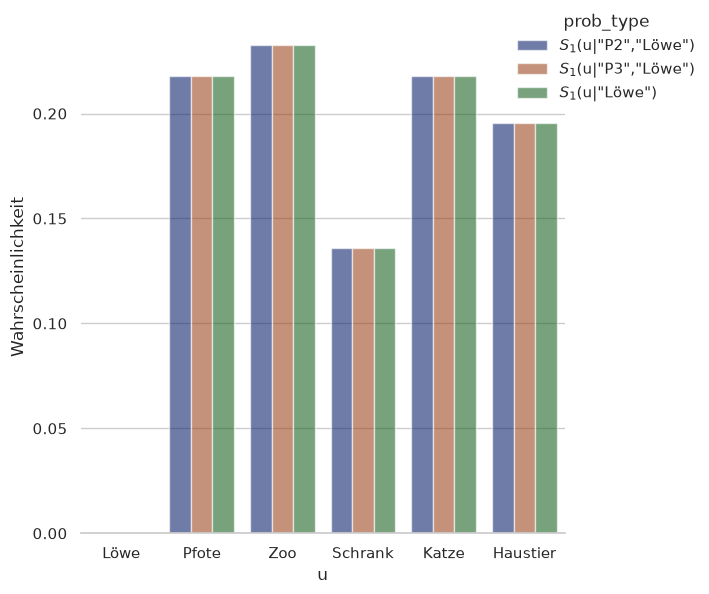

In [67]:
def run_experiment(agent, output_folder="../output/e1"):
    pathlib.Path(output_folder).mkdir(parents=True, exist_ok=True) 
    word_rows = []
    word_rows_certain = []
    for u in gs.V:

        t_prob = agent.L0_t(u, gs.TARGET)
        i_prob =  agent.L0_a(u, ("P3",gs.TARGET))
        s1_prob = agent.S1_i_t(u, "P3", gs.TARGET, adversarial=True)

        s1_prob_p2 = agent.S1_i_t(u, "P2", gs.TARGET, adversarial=True)
        s1_prob_p3 = agent.S1_i_t(u, "P3", gs.TARGET, adversarial=True)
        s1_prob_certain = agent.S1_certain(u, gs.TARGET)

        for prob_name, prob in zip(["L0_t", "L0_i", "S1"], [t_prob, i_prob, s1_prob]):
            row_dic = {"word": u, "prob_type": prob_name, "prob": prob}
            word_rows.append(row_dic)    
        for prob_name, prob in zip(["S1_p2", "S1_p3", "S1_certain"], [s1_prob_p2, s1_prob_p3, s1_prob_certain]):
            row_dic = {"word": u, "prob_type": prob_name, "prob": prob}
            word_rows_certain.append(row_dic)

    with open(output_folder + "/l_rows.json", "w") as final:
	    json.dump(word_rows, final) 
    
    with open(output_folder + "/s_rows.json", "w") as final:
	    json.dump(word_rows_certain, final)       
    
    create_L_diagram(word_rows, output_file=output_folder + "/L_plot.png")
    create_S_diagram(word_rows_certain, output_file=output_folder + "/S_plot.png")

    return
    

run_experiment(a1)

NameError: name 'output_ps' is not defined

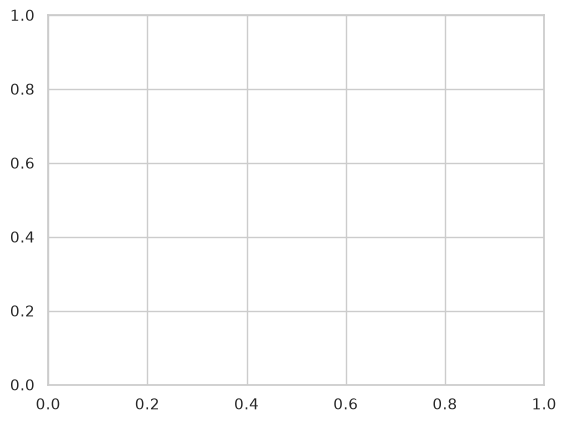

In [52]:
fig, ax = plt.subplots()
ax.bar(gs.V, output_ps)
plt.xticks(rotation=90)
plt.show()


# normalization leads to s1 probabilities looking almost the same 
# maybe don't normalize and just subtract the lowest value from each number instead (except for the target)

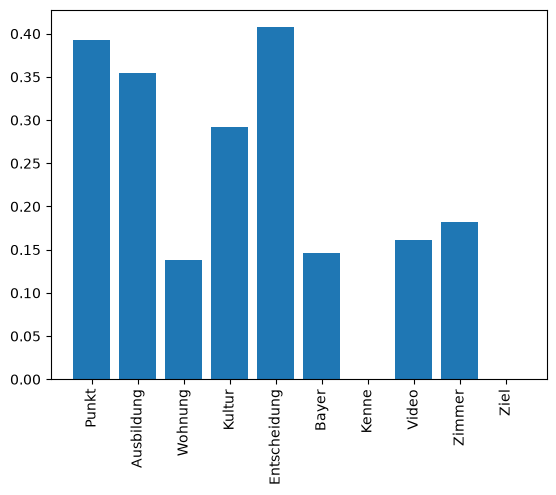

In [8]:
fig, ax = plt.subplots()
ax.bar(gs.V, gs.SIMS[gs.V.index(gs.TARGET)])
plt.xticks(rotation=90)
plt.show()

In [33]:
a1.L0_a(gs.V[2], (gs.PLAYERS[0], gs.TARGET))

np.float64(0.6056470120084698)

In [39]:
prob_per_u = [a1.S1_certain(u, gs.TARGET) for u in gs.V]
print(prob_per_u)


C:\Users\Hannes\AppData\Local\Temp\ipykernel_12460\2786098677.py:118: RuntimeWarning: divide by zero encountered in log
  U = np.log(x * self.L0_t(u,t,listener=i)) - np.log(self.L0_a(u,(i,t),listener=partner, speaker=speaker))
C:\Users\Hannes\AppData\Local\Temp\ipykernel_12460\2786098677.py:118: RuntimeWarning: invalid value encountered in scalar subtract
  U = np.log(x * self.L0_t(u,t,listener=i)) - np.log(self.L0_a(u,(i,t),listener=partner, speaker=speaker))
C:\Users\Hannes\AppData\Local\Temp\ipykernel_12460\2786098677.py:120: RuntimeWarning: divide by zero encountered in log
  logger.info(f"imposter component of utility function: {np.log(x * self.L0_t(u,t,listener=i))}\nagent component of utility function: {-np.log(self.L0_a(u,(i,t),listener=partner, speaker=speaker))}")


[np.float64(0.07860700122204078), np.float64(0.10257612379252906), np.float64(0.09518372649522834), np.float64(0.11957786619919859), np.float64(0.07989406039142972), np.float64(0.0), np.float64(0.20957542000953439), np.float64(0.15618609592391947), np.float64(0.06950362156707365), np.float64(0.08889608439904603)]


In [34]:
print(gs.SIMS[5])

[0.23703232 0.36651731 0.41496426 0.51218992 0.21370074 0.
 0.99999988 0.8254742  0.12148467 0.18236418 0.19101942]


In [32]:
print(gs.V.index(gs.TARGET))

5


In [ ]:
a1 = Agent("P1")

In [15]:
print(a1.priors)

{'P1': {'agent': {'i': array([0. , 0.5, 0.5]), 't': array([0, 0, 0, 0, 0, 0, 1, 0, 0, 0])}}, 'P2': {'imposter': {'i': array([0, 0, 1]), 't': array([0.02902473, 0.07805299, 0.0196113 , 0.22553   , 0.47067129,
       0.0138848 , 0.0241219 , 0.01829735, 0.05275441, 0.06805122])}, 'agent': {'i': array([0.5, 0. , 0.5]), 't': array([0, 0, 0, 0, 0, 0, 1, 0, 0, 0])}}, 'P3': {'imposter': {'i': array([0, 0, 1]), 't': array([0.02902473, 0.07805299, 0.0196113 , 0.22553   , 0.47067129,
       0.0138848 , 0.0241219 , 0.01829735, 0.05275441, 0.06805122])}, 'agent': {'i': array([0.5, 0.5, 0. ]), 't': array([0, 0, 0, 0, 0, 0, 1, 0, 0, 0])}}}


In [16]:
print(a1.targets_imp)

{'P2': 'Online', 'P3': 'Online'}


In [17]:
print(gs.V)

['Notwendigkeit', 'Zugang', 'Glanz', 'Band', 'Online', 'Fussballer', 'Filter', 'Erholung', 'U00', 'Produkt']


In [11]:
print(a1.S1_certain("Glanz",gs.TARGET))

utterance: Glanz, imposter: P2
x: 5
l0_t: 0.028088129337034272
l0_i: 0.5814059684003207
U:  -1.4206642976410255
utterance: Notwendigkeit, imposter: P2
x: 5
l0_t: 0.02340952655135881
l0_i: 0.5128091937786018
U:  -1.4773228645038459
utterance: Zugang, imposter: P2
x: 5
l0_t: 0.02862558268711568
l0_i: 0.5869106003173427
U:  -1.4111337789572613
utterance: Glanz, imposter: P2
x: 5
l0_t: 0.028088129337034272
l0_i: 0.5814059684003207
U:  -1.4206642976410255
utterance: Band, imposter: P2
x: 5
l0_t: 0.039625822699804934
l0_i: 0.5727179436298019
U:  -1.0614744439920396
utterance: Online, imposter: P2
x: 5
l0_t: 0.01846034109124766
l0_i: 1.0
U:  -2.3826926603283427
utterance: Fussballer, imposter: P2
x: 5
l0_t: 0.03043759135960442
l0_i: 0.4521971635361458
U:  -1.0890019724171855
utterance: Filter, imposter: P2
x: 5
l0_t: 0.0
l0_i: 0.0
U:  nan
utterance: Erholung, imposter: P2
x: 5
l0_t: 0.06359522902368878
l0_i: 0.7925398570092651
U:  -0.9132664326273886
utterance: U00, imposter: P2
x: 5
l0_t: 0.

/tmp/ipykernel_56655/58310932.py:166: RuntimeWarning: divide by zero encountered in log
  U = np.log(x * self.L0_t(u,t,listener=imp)) - np.log(self.L0_i(u,i,listener=partner, speaker=speaker, role="agent"))
/tmp/ipykernel_56655/58310932.py:166: RuntimeWarning: invalid value encountered in scalar subtract
  U = np.log(x * self.L0_t(u,t,listener=imp)) - np.log(self.L0_i(u,i,listener=partner, speaker=speaker, role="agent"))


In [18]:
for u in gs.V: 
    print(u, a1.S1_certain(u, gs.TARGET))

/tmp/ipykernel_56655/4132279315.py:166: RuntimeWarning: divide by zero encountered in log
  U = np.log(x * self.L0_t(u,t,listener=imp)) - np.log(self.L0_i(u,i,listener=partner, speaker=speaker, role="agent"))
/tmp/ipykernel_56655/4132279315.py:166: RuntimeWarning: invalid value encountered in scalar subtract
  U = np.log(x * self.L0_t(u,t,listener=imp)) - np.log(self.L0_i(u,i,listener=partner, speaker=speaker, role="agent"))


Notwendigkeit 0.0987303738393634
Zugang 0.10548636719276597
Glanz 0.1044858029210875
Band 0.1496412942614111
Online 0.03992580442389372
Fussballer 0.14557821905719098
Filter nan
Erholung 0.17354710654069466
U00 0.08445900239095722
Produkt 0.09814602937263546


In [19]:
for u in gs.V: 
    print(u, a1.L0_i(u, "P3", listener="P2", speaker="P1", role="agent"))


Notwendigkeit 0.5128091937786018
Zugang 0.5869106003173427
Glanz 0.5814059684003207
Band 0.5727179436298019
Online 1.0
Fussballer 0.4521971635361458
Filter 0.0
Erholung 0.7925398570092651
U00 0.5386199945015109
Produkt 0.44339620854005163


In [20]:
for w in gs.V: 
    print(w, a1.L0_t(w, gs.TARGET))

Notwendigkeit 0.02340952655135881
Zugang 0.02862558268711568
Glanz 0.028088129337034272
Band 0.039625822699804934
Online 0.01846034109124766
Fussballer 0.03043759135960442
Filter 0.0
Erholung 0.06359522902368878
U00 0.02103364136231078
Produkt 0.020121055346171063


In [17]:
for u in gs.V: 
    print(u, a1.S1_i_t(u, "P3", gs.TARGET))

Notwendigkeit 0.10929112730416304
Zugang 0.11601944723483582
Glanz 0.10210478561764874
Band nan
Online 0.14475802748668862
Fussballer 0.10887003090067895
Filter 0.11724359739350286
Erholung 0.11088138548380169
U00 0.10165435038108561
Produkt 0.08917724819759464


/tmp/ipykernel_250123/3214175140.py:164: RuntimeWarning: divide by zero encountered in log
  U = np.log(self.L0_t(u,t,listener=imp)) - np.log(self.L0_i(u,i,listener=partner, speaker=speaker, role="agent"))
/tmp/ipykernel_250123/3214175140.py:164: RuntimeWarning: invalid value encountered in scalar subtract
  U = np.log(self.L0_t(u,t,listener=imp)) - np.log(self.L0_i(u,i,listener=partner, speaker=speaker, role="agent"))


In [20]:
for u in range(len(gs.V)): 
    print(gs.V[u], gs.SIMS[gs.V.index(gs.TARGET), u])

Notwendigkeit 0.508949875831604
Zugang 0.50888991355896
Glanz 0.5427209138870239
Band 0.0
Online 1.0
Fussballer 0.4384180009365082
Filter 0.5121899247169495
Erholung 0.5876442790031433
U00 0.3837636709213257
Produkt 0.17019608616828918


In [ ]:
def main(): 
    player_dic = {}
    for p in gs.PLAYERS: 
        role = gs.ROLES[p]
        knows_imp = True if role=="imposter" else False
        player_dic[p] = Agent(p, knows_imp=knows_imp)

        

In [5]:
P1 = Agent("P1", knows_imp=True)


print(gs.TARGET)
print(gs.V.index(gs.TARGET))
print(P1.target_imp)
print(gs.PLAYERS)

Fussballer
5
Online
['P1', 'P2', 'P3']


In [6]:
print(P1.priors)

{'P1': array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.]]), 'P2': array([[0. , 0. , 0. , 0. , 0. , 0.5, 0. , 0. , 0. , 0. ],
       [0. , 0. , 0. , 0. , 0. , 0. , 0. , 0. , 0. , 0. ],
       [0. , 0. , 0. , 0. , 0. , 0.5, 0. , 0. , 0. , 0. ]]), 'P3': array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.02902473, 0.07805299, 0.0196113 , 0.22553   , 0.47067129,
        0.0138848 , 0.0241219 , 0.01829735, 0.05275441, 0.06805122]])}


In [7]:
P1.listen("Glanz", "P2")

/tmp/ipykernel_8596/2691900590.py:96: RuntimeWarning: divide by zero encountered in log
  U = np.log(self.L0(u,w,listener=partner, speaker=speaker)) + np.log(self.L0(u,(imp,w[1]),listener=imp, speaker=speaker)) # weil auf logarithmischer Skala negativ
/tmp/ipykernel_8596/2691900590.py:106: RuntimeWarning: invalid value encountered in scalar divide
  P_u_w = P_u_w/SUM


posteriors P1: [[nan nan nan nan nan  0. nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan  1. nan nan nan nan]]
posteriors P3: [[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.03095438 0.17600298 0.         0.27600147 0.39458675 0.01299215
  0.02808813 0.015005   0.02448395 0.04188519]]


In [8]:
P1.target_imp

'Online'

In [9]:
P1.S1(gs.V[0], ("P3", gs.TARGET))

/tmp/ipykernel_8596/2691900590.py:96: RuntimeWarning: divide by zero encountered in log
  U = np.log(self.L0(u,w,listener=partner, speaker=speaker)) + np.log(self.L0(u,(imp,w[1]),listener=imp, speaker=speaker)) # weil auf logarithmischer Skala negativ


np.float64(0.031257468918548595)

In [10]:
P1.target_imp

'Online'

In [11]:
P1.L0("Zugang", ("P3", gs.TARGET), listener="P3", speaker="P2")

np.float64(0.014965368474864337)

In [12]:
P1.L0("Zugang", ("P1", gs.TARGET), listener="P2", speaker="P1")

np.float64(0.4347317054516399)

In [13]:
P1.L1(gs.V[2], ("P3",gs.TARGET), speaker="P1", listener="P2")

/tmp/ipykernel_8596/2691900590.py:96: RuntimeWarning: divide by zero encountered in log
  U = np.log(self.L0(u,w,listener=partner, speaker=speaker)) + np.log(self.L0(u,(imp,w[1]),listener=imp, speaker=speaker)) # weil auf logarithmischer Skala negativ
/tmp/ipykernel_8596/2691900590.py:106: RuntimeWarning: invalid value encountered in scalar divide
  P_u_w = P_u_w/SUM


np.float64(0.3606086300942638)

In [14]:
P1.L0(gs.V[6], ("P3",gs.TARGET))

np.float64(0.8239263146121298)

In [15]:
print(gs.TARGET)
print(P1.target_imp)

Fussballer
Online


In [16]:
for u in gs.V:
    p_w_u = P1.S1(u,("P3",gs.TARGET))
    print(f"u: {u}, P(w|u): {p_w_u}")

/tmp/ipykernel_8596/2691900590.py:96: RuntimeWarning: divide by zero encountered in log
  U = np.log(self.L0(u,w,listener=partner, speaker=speaker)) + np.log(self.L0(u,(imp,w[1]),listener=imp, speaker=speaker)) # weil auf logarithmischer Skala negativ


u: Notwendigkeit, P(w|u): 0.031257468918548595
u: Zugang, P(w|u): 0.08554315717054087
u: Glanz, P(w|u): 0.06117098541898671
u: Band, P(w|u): 0.10689040471083684
u: Online, P(w|u): 0.07658849126323501
u: Fussballer, P(w|u): 0.0
u: Filter, P(w|u): 0.351638658316185
u: Erholung, P(w|u): 0.21629221220461559
u: U00, P(w|u): 0.01920645866754007
u: Produkt, P(w|u): 0.05141216332951143


In [17]:
print(gs.ROLES)

{'P1': 'agent', 'P2': 'agent', 'P3': 'imposter'}


In [18]:
for k,v in P1.priors.items():
    print(f"{k}: {v}")

P1: [[nan nan nan nan nan  0. nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan  1. nan nan nan nan]]
P2: [[0.  0.  0.  0.  0.  0.5 0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.5 0.  0.  0.  0. ]]
P3: [[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.02998956 0.12702799 0.00980565 0.25076573 0.43262902 0.01343848
  0.02610502 0.01665117 0.03861918 0.05496821]]


## next steps 

- implement speaker that doesn't know imposter identity
    - do speakers need to explicitely reason about different worlds or is this manageable with the priors only? 
- implement listeners adjusting priors 
- implement imposter 
    - speaking 
    - adjusting priors (about target) 
- implement agents modelling imposter adjusting target probabilities

## questions 

- do (models of) listeners actually have to reason about imposter identity to calculate judgements at all? Am I giving information to the models that they shouldn't actually have? 
- does the utility function actually work the way it's supposed to (penalizing words too close to the target word)?
    - should I add a modifier to the imposter part? 
- 


In [33]:
with open('../output/random_nouns.json', 'r') as file:
    rd_100 = json.load(file)

print(rd_100)


['Ball', 'Künstler', 'Spaziergang', 'Partnerin', 'Bayer', 'Ereignis', 'Feuerwehr', 'Petition', 'Bundestag', 'Erfüllung', 'Ausweis', 'Rückkehr', 'Zitat', 'Verfasst', 'Schülerin', 'Wette', 'Aluminium', 'Saal', 'Einbezog', 'Eign', 'Klinik', 'Playstation', 'Nutze', 'Zufriedenheit', 'Opposition', 'Schweine', 'Messung', 'Steigerung', 'Hafen', 'Service', 'Zwischenzeit', 'Kenntnis', 'Rest', 'Terrorismus', 'Ulm', 'Wettbewerb', 'Freund', 'Element', 'Anwohner', 'Bgb', 'Empfänger', 'Rufe', 'Station', 'Milde', 'Gefasst', 'Invasion', 'Herauszufinde', 'Gewalt', 'Realschule', 'Solidarität', 'Produkt', 'Koffer', 'Mann', 'Verbrechen', 'Weisheit', 'Kontinent', 'Komplex', 'Pressemitteilung', 'Vorteil', 'Doktor', 'Symbol', 'Tasse', 'Scheidung', 'Stürmer', 'Statistik', 'Christ', 'Rundschau', 'Furcht', 'Dialog', 'Partie', 'Nation', 'Haus', 'Jungfrau', 'Tiger', 'Zieh', 'Rufe', 'Hochschule', 'Vorwurf', 'Rechtsprechung', 'Hotel', 'Fahrt', 'Wahrheit', 'Meinung', 'Verkehrt', 'Zwischenzeitlich', 'Einleitung', 'Nac

In [ ]:
class Imposter:
    def __init__(self, player): 
         self.player = player
         self.role = roles[player]
         self.target = self.get_target()
         self.P_t = freq.copy()
         self.alpha = rationality[player]
         self.target_imp = self.get_target()

    def get_target(self):
        mv = max(freq.values())
        res = [k for k in freq if freq[k] == mv]
        return(rd.choice(res))
    
    
    def L0(self, u, t, p_player = [2/3, 1/3]):
        p_agent = get_similarity(u,t) * p_player[0]
        p_imposter = get_similarity(u,self.target_imp) * p_player[1]
        p_agent_norm = p_agent/(p_agent + p_imposter)
        p_imposter_norm = p_imposter/(p_agent + p_imposter)
        return((p_agent_norm, p_imposter_norm))

    def S1(self, t):
        p_distr = []
        for u in V: 
            # what exactly is the world? The persona the player wants to communicate? That would always be agent.
            p_u = np.exp(self.alpha * (np.log(self.L0(u, t)[0])- C[u]))
            #print("p_u:", p_u)
            p_distr.append(p_u)

        p_sum = sum(p_distr)
        u_dic = {u: p/p_sum for u,p in zip(V,p_distr)}
        #print(p_distr)
        #print(u_dic)
        return(u_dic)

    def choose_u(self): 
        P_u = self.S1(self.target)
        mv = max(P_u.values())
        res = [k for k in P_u if P_u[k] == mv]
        return(rd.choice(res))
    

    def L1(self, u):
        t_distr = []
        for t in V: 
            p = self.S1(t)[u] * self.P_t[t]
            t_distr.append(p)

        p_sum = sum(t_distr)
        t_dic = {t: p/p_sum for t,p in zip(V,t_distr)}

        # is the new probability distribution a mix of the old distribution and the newly calculated one or is it just the new one? 
        self.P_t = t_dic

        return(t_dic)
    



class GameState:
    def __init__(self): 
        self.previous_words = []

    def say_word(self, word):
        self.previous_words += word